## 03 – Business Impact: How Much Would the Model Save?

**Goal:** Turn the model's results into money, and find the cut-off that saves the most.

**From notebook 2:** the random forest was the best model, catching 68 of 95 frauds in the test set with only 5 false alarms,
using the default cut-off of 50%.

**Steps:** load the saved model → calculate savings at every cut-off → find the best one → recommendation.

### Load the model

Load the trained random forest and the test data saved at the end of `02_modelling.ipynb`, so nothing needs retraining.

In [2]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

forest, X_test, y_test = joblib.load("../models/random_forest.joblib")
print(f"Loaded model and test set: {len(X_test):,} transactions ({int(y_test.sum())} fraud)")

Loaded model and test set: 56,746 transactions (95 fraud)


### How savings are calculated

The model gives every transaction a fraud probability. The **cut-off** decides how high it must be to flag the transaction (default: 50%).
- A **lower** cut-off catches more fraud, but flags more genuine customers by mistake.
- A **higher** cut-off causes fewer false alarms, but lets more fraud through.

Simple cost assumptions:
- **Catching a fraud** saves the transaction amount.
- **A false alarm** costs **5** (customer support time and a frustrated customer).

**Net savings = money saved from caught fraud − cost of false alarms.** The code tries every cut-off from 1% to 99% and finds the one with the highest net savings.

In [ ]:
FALSE_ALARM_COST = 5

probabilities = forest.predict_proba(X_test)[:, 1]   #fraud probability for each transaction
amounts = X_test["Amount"].values
is_fraud = y_test.values == 1
total_fraud_value = amounts[is_fraud].sum()

rows = []
for threshold in [i / 100 for i in range(1, 100)]:
    flagged = probabilities >= threshold        #transactions the model would flag
    caught = flagged & is_fraud                 #flagged AND really fraud
    false_alarms = flagged & ~is_fraud          #flagged but actually normal
    money_saved = amounts[caught].sum()
    alarm_cost = false_alarms.sum() * FALSE_ALARM_COST
    rows.append({
        "cut_off": threshold,
        "fraud_caught": caught.sum(),
        "false_alarms": false_alarms.sum(),
        "money_saved": money_saved,
        "net_savings": money_saved - alarm_cost,
    })

impact = pd.DataFrame(rows)
best = impact.loc[impact["net_savings"].idxmax()]
default = impact.loc[impact["cut_off"] == 0.5].iloc[0]

print(f"Total value of fraud in test set: {total_fraud_value:,.2f}\n")
print(f"Default cut-off (50%): catches {int(default['fraud_caught'])} of 95, "
      f"{int(default['false_alarms'])} false alarms, net savings {default['net_savings']:,.2f}")
print(f"Best cut-off ({best['cut_off']:.0%}): catches {int(best['fraud_caught'])} of 95, "
      f"{int(best['false_alarms'])} false alarms, net savings {best['net_savings']:,.2f}")
print(f"\nThe best cut-off saves {best['net_savings'] / total_fraud_value:.0%} of the total value of fraud.")

Total value of fraud in test set: 14,766.31

Default cut-off (50%): catches 69 of 95, 5 false alarms, net savings 8,879.42
Best cut-off (4%): catches 77 of 95, 87 false alarms, net savings 11,265.18

The best cut-off saves 76% of the total value of fraud.


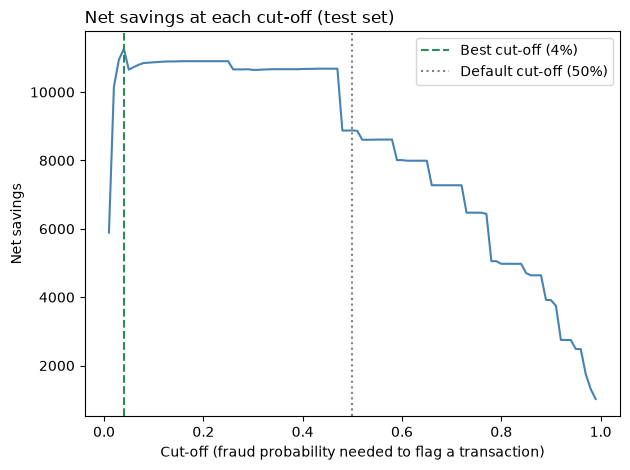

In [5]:
fig, ax = plt.subplots()
ax.plot(impact["cut_off"], impact["net_savings"], color="steelblue")
ax.axvline(best["cut_off"], linestyle="--", color="seagreen", label=f"Best cut-off ({best['cut_off']:.0%})")
ax.axvline(0.5, linestyle=":", color="grey", label="Default cut-off (50%)")
ax.set_xlabel("Cut-off (fraud probability needed to flag a transaction)")
ax.set_ylabel("Net savings")
ax.set_title("Net savings at each cut-off (test set)", loc="left")
ax.legend()
plt.tight_layout()
plt.savefig("../images/net_savings_by_cutoff.png", dpi=150)
plt.show()

In [ ]:
#Compare a few cut-offs side by side
impact[impact["cut_off"].isin([0.04, 0.10, 0.15, 0.20, 0.50])].round(2)

,cut_off,fraud_caught,false_alarms,money_saved,net_savings
3,0.04,77,87,11700.18,11265.18
9,0.10,75,21,10975.97,10870.97
14,0.15,74,15,10975.97,10900.97
19,0.20,73,14,10973.75,10903.75
49,0.50,69,5,8904.42,8879.42


### Findings and recommendation

- **Default cut-off (50%):** catches 69 of 95 frauds with 5 false alarms, net savings of **8,879**.
- **Best cut-off (4%):** catches 77 of 95 frauds with 87 false alarms, net savings of **11,265**,
  about **27% more** than the default, and **76%** of the total value of fraud (14,766).
- **Lowering the cut-off pays off, but only up to a point.** Savings stay high and fairly flat between about 4% and 47%,
  but collapse below 3%, where false alarms overwhelm the savings.

**Recommendation:** lower the cut-off from 50% to somewhere in the **10–20%** range. This captures almost all of the extra savings
(around 10,900), while staying safely away from the steep drop below 3%, where small changes in real-world data could make results much worse.

**Limitations:**
- The false alarm cost of 5 is an assumption. A real bank would use its own figure, which would move the best cut-off.
- The cut-off was chosen using the test set, so these savings are slightly optimistic. Ideally it would be chosen on separate data.
- Results cover only the test set (20% of two days of transactions). Scaled to a full year of a bank's transactions, the savings would be far larger.